# Retrievals: JAX Runtime Native Tutorial

This notebook is a runtime-native, JAXNS-based rewrite of the advanced retrieval workflow.

It focuses on the current retrieval runtime introduced in the latest update:

- the forward model uses the runtime-native `(model_context, physical_params, pt_plot_mode=False)` interface,
- the retrieval uses `sampler_type="jaxns"`,
- two observation objects share one forward-model evaluation through `external_radtrans_reference`,
- the notebook inspects the constructed runtime to confirm that the model group is truly `runtime_native`.

The example remains intentionally lightweight enough to run on a workstation, while still demonstrating the current advanced API surface.

## Before you start

This notebook assumes that the pRT input data are already installed and that the JAX stack is available in the active environment.

Unlike the legacy advanced tutorial, this notebook does not rely on `pymultinest`, and it does not use the legacy `prt_object, parameters` model signature.

In [1]:
import os
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("JAX_CHECK_TRACER_LEAKS", "False")

multinest_lib_dir = "/Users/nasedkin/software/MultiNest/lib/"
existing_dyld_path = os.environ.get("DYLD_LIBRARY_PATH", "")
if multinest_lib_dir not in existing_dyld_path.split(":"):
    os.environ["DYLD_LIBRARY_PATH"] = (
        f"{multinest_lib_dir}:{existing_dyld_path}"
        if existing_dyld_path else multinest_lib_dir
    )

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import tensorflow_probability.substrates.jax as tfp

from petitRADTRANS import physical_constants as cst
from petitRADTRANS.retrieval import Retrieval, RetrievalConfig
from petitRADTRANS.retrieval.models import (
    calculate_transmission_spectrum_runtime,
    mark_model_function_runtime_native,
    )
from petitRADTRANS.retrieval.runtime import ModelInputs, ModelResult

tfpd = tfp.distributions
jax.config.update("jax_enable_x64", True)

print(f"JAX devices: {jax.devices()}")

/Users/nasedkin/python-packages/jaxns/src/jaxns/internals/mixed_precision.py:14: UserWarning: JAX x64 is not enabled. Setting it now. Check for errors.
  warnings.warn("JAX x64 is not enabled. Setting it now. Check for errors.")


JAX devices: [CpuDevice(id=0)]


In [3]:
candidate_paths = [
    Path("retrievals/transmission/observations/HST/hst_example_clear_spec.txt"),
    Path("docs/content/notebooks/retrievals/transmission/observations/HST/hst_example_clear_spec.txt"),
    Path("observations/hst_example_clear_spec.txt"),
]

for candidate in candidate_paths:
    if candidate.exists():
        example_data_file = candidate.resolve()
        break
else:
    raise FileNotFoundError(
        "Could not locate hst_example_clear_spec.txt. Try running the notebook from the repo root or from docs/content/notebooks."
    )

output_root = example_data_file.parents[4] / "runs" / "retrieval_jax_runtime"
output_root.mkdir(parents=True, exist_ok=True)

observations = np.loadtxt(example_data_file)
wavelengths_all = observations[:, 0]
spectrum_all = observations[:, 1]
uncertainties_all = observations[:, 2]

split_wavelength = float(np.median(wavelengths_all))
blue_mask = wavelengths_all <= split_wavelength
red_mask = ~blue_mask

wavelength_boundaries = (0.95 * float(wavelengths_all.min()), 1.05 * float(wavelengths_all.max()))

print(f"Using observation file: {example_data_file}")
print(f"Output directory: {output_root}")
print(f"Blue points: {blue_mask.sum()}, red points: {red_mask.sum()}")

Using observation file: /Users/nasedkin/python-packages/petitRADTRANS/docs/content/notebooks/retrievals/transmission/observations/HST/hst_example_clear_spec.txt
Output directory: /Users/nasedkin/python-packages/petitRADTRANS/docs/content/notebooks/runs/retrieval_jax_runtime
Blue points: 10, red points: 10


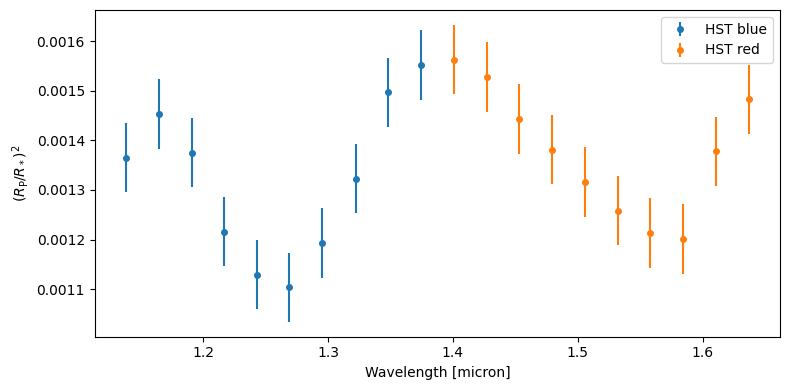

In [4]:
plt.figure(figsize=(8, 4))
plt.errorbar(wavelengths_all[blue_mask], spectrum_all[blue_mask], yerr=uncertainties_all[blue_mask], fmt='o', ms=4, label='HST blue')
plt.errorbar(wavelengths_all[red_mask], spectrum_all[red_mask], yerr=uncertainties_all[red_mask], fmt='o', ms=4, label='HST red')
plt.xlabel('Wavelength [micron]')
plt.ylabel(r'$(R_{\rm P}/R_*)^2$')
plt.legend()
plt.tight_layout()

## A true runtime-native model

The model below uses the runtime-native signature directly. It constructs `ModelInputs` from a pressure grid and a small set of retrieved physical parameters, then delegates the radiative-transfer evaluation to `calculate_transmission_spectrum_runtime`.

This keeps the model compatible with the JAX retrieval runtime and with JAXNS guard checks that require a `runtime_native` model group.

In [5]:
pressures = jnp.logspace(-6.0, 2.0, 100)

def _constant_profile(value):
    return jnp.full_like(pressures, jnp.asarray(value, dtype=jnp.float64))

@mark_model_function_runtime_native
def h2o_transmission(model_context, physical_params, pt_plot_mode=False):
    temperature = physical_params.get("temperature")
    log_g = physical_params.get("log_g")
    planet_radius = physical_params.get("planet_radius")
    stellar_radius = physical_params.get("stellar_radius")
    reference_pressure = physical_params.get("reference_pressure")
    log_h2o = physical_params.get("log_H2O")
    log_pcloud = physical_params.get("log_Pcloud")

    temperatures = _constant_profile(temperature)

    if pt_plot_mode:
        return ModelResult(
            kind="pt_profile",
            pressures=pressures,
            temperatures=temperatures,
        )

    h2o_mass_fraction = jnp.power(10.0, log_h2o)
    remainder = jnp.clip(1.0 - h2o_mass_fraction, 1e-12, 1.0)

    abundances = {
        "1H2-16O__POKAZATEL": _constant_profile(h2o_mass_fraction),
        "H2": _constant_profile(0.74 * remainder),
        "He": _constant_profile(0.26 * remainder),
    }

    model_inputs = ModelInputs(
        pressures=pressures,
        temperatures=temperatures,
        abundances=abundances,
        mean_molar_masses=_constant_profile(2.33),
        gravity=jnp.power(10.0, log_g),
        planet_radius=planet_radius,
        stellar_radius=stellar_radius,
        reference_pressure=reference_pressure,
        opaque_cloud_top_pressure=jnp.power(10.0, log_pcloud),
    )

    return calculate_transmission_spectrum_runtime(model_context, model_inputs)

## Retrieval configuration

This setup keeps the physics intentionally compact, but still includes two advanced features:

- a custom runtime-native forward model,
- two observation objects that share a single pRT evaluation through `external_radtrans_reference`.

In [ ]:
retrieval_config = RetrievalConfig(
    retrieval_name="hst_runtime_native_jaxns",
    run_mode="retrieval",
    sampler_type="jaxns",
    adaptive_mesh_refinement=False,
    scattering_in_emission=False,
    pressures=pressures,
)

retrieval_config.add_parameter(
    name="stellar_radius",
    is_free_parameter=False,
    value=0.651 * cst.r_sun,
    plot_in_corner=False,
)
retrieval_config.add_parameter(
    name="reference_pressure",
    is_free_parameter=False,
    value=0.01,
    plot_in_corner=False,
)

retrieval_config.add_parameter(
    name="log_g",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=2.5, high=4.5),
    plot_in_corner=True,
    corner_ranges=(2.5, 4.5),
    corner_label=r"$\log(g)$",
)
retrieval_config.add_parameter(
    name="planet_radius",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=0.20 * cst.r_jup, high=0.40 * cst.r_jup),
    plot_in_corner=True,
    corner_ranges=(0.20, 0.40),
    corner_label=r"R$_{pl}$",
    corner_transform=lambda radius: radius / cst.r_jup_mean,
)
retrieval_config.add_parameter(
    name="temperature",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=400.0, high=1400.0),
    plot_in_corner=True,
    corner_ranges=(400.0, 1400.0),
    corner_label="Temp",
)
retrieval_config.add_parameter(
    name="log_H2O",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=-8.0, high=-2.0),
    plot_in_corner=True,
    corner_ranges=(-8.0, -2.0),
    corner_label=r"$\log X_{H_2O}$",
)
retrieval_config.add_parameter(
    name="log_Pcloud",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=-6.0, high=2.0),
    plot_in_corner=True,
    corner_ranges=(-6.0, 2.0),
    corner_label=r"$\log P_{cl}$",
)

retrieval_config.set_rayleigh_species(["H2", "He"])
retrieval_config.set_continuum_opacities(["H2--H2", "H2--He"])
retrieval_config.set_line_species(["1H2-16O__POKAZATEL"], use_equilibrium_chemistry=False)

retrieval_config.add_data(
    name="HST_blue",
    path_to_observations=None,
    model_generating_function=h2o_transmission,
    wavelengths=wavelengths_all[blue_mask],
    spectrum=spectrum_all[blue_mask],
    uncertainties=uncertainties_all[blue_mask],
    wavelength_boundaries=wavelength_boundaries,
    data_resolution=60,
    model_resolution=None,
    line_opacity_mode="c-k",
)

retrieval_config.add_data(
    name="HST_red",
    path_to_observations=None,
    model_generating_function=None,
    wavelengths=wavelengths_all[red_mask],
    spectrum=spectrum_all[red_mask],
    uncertainties=uncertainties_all[red_mask],
    wavelength_boundaries=wavelength_boundaries,
    data_resolution=60,
    model_resolution=None,
    line_opacity_mode="c-k",
    external_radtrans_reference="HST_blue",
)


In [ ]:
retrieval = Retrieval(
    configuration=retrieval_config,
    output_directory=str(output_root),
    use_mpi=False,
    evaluate_sample_spectra=False,
    use_prt_plot_style=True,
)

runtime = retrieval._get_runtime()
for group in runtime.model_groups:
    print({
        "source_name": group.source_name,
        "model_contract": group.model_contract,
        "observation_names": group.observation_names,
    })

# Set up plotting — these attributes live on the RetrievalPlotter after Retrieval is created
# Define axis properties of spectral plot if run_mode == 'evaluate'
retrieval.plotter.spec_xlabel = 'Wavelength [micron]'
retrieval.plotter.spec_ylabel = "Flux [W/m2/micron]"
retrieval.plotter.y_axis_scaling = 1.0
retrieval.plotter.xscale = 'log'
retrieval.plotter.yscale = 'linear'
retrieval.plotter.resolution = 100.0  # maximum resolution, will rebin the data
retrieval.plotter.nsample = 100  # if we want a plot with many sampled spectra

# Define from which observation object to take P-T in evaluation mode, add PT-envelope plotting options
retrieval.plotter.reference_data_name = 'GRAVITY'
retrieval.plotter.temp_limits = [150, 3000]
retrieval.plotter.press_limits = [1e2, 1e-5]

Setting up Radtrans object for data 'HST_blue'...
Loading Radtrans opacities...


/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(
/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(
/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(
/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src

 Loading line opacities of species '1H2-16O__POKAZATEL' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R1000_0.3-50mu.ktable.petitRADTRANS.h5'...

/opt/anaconda3/envs/jaxprt/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(


 Done.
 Successfully loaded all line opacities
 Loading CIA opacities for H2--H2 from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/continuum/collision_induced_absorptions/H2--H2/H2--H2-NatAbund/H2--H2-NatAbund__BoRi.R831_0.6-250mu.ciatable.petitRADTRANS.h5'... Done.
 Loading CIA opacities for H2--He from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/continuum/collision_induced_absorptions/H2--He/H2--He-NatAbund/H2--He-NatAbund__BoRi.DeltaWavenumber2_0.5-500mu.ciatable.petitRADTRANS.h5'... Done.
 Successfully loaded all CIA opacities
Successfully loaded all opacities
{'source_name': 'HST_blue', 'model_contract': 'runtime_native', 'observation_names': ('HST_blue', 'HST_red')}


The runtime inspection above should show one grouped model evaluation shared by `HST_blue` and `HST_red`, and that group should have `model_contract='runtime_native'`. That is the condition required by the JAXNS retrieval path.

## Running JAXNS

Set `run_retrieval = True` to execute the retrieval. The notebook keeps the default as `False` so that opening it does not start a nested sampler immediately.

This example uses deliberately small settings for an interactive notebook. For science runs, increase `num_live_points` and `max_samples`.

In [ ]:
run_retrieval = False

In [ ]:
if run_retrieval:
    retrieval.run(
        num_live_points=60,
        max_samples=50_000,
        s=4,
        k=0,
        c=200,
        shell_fraction=0.5,
        gradient_guided=False,
        init_efficiency_threshold=0.05,
        verbose=True,
        jit=True,
        seed=12345,
    )

In [ ]:
if run_retrieval:
    free_parameter_names = [
        name
        for name, parameter in retrieval.configuration.parameters.items()
        if parameter.is_free_parameter
    ]

    summary = retrieval.sampler.get_summary(free_parameter_names=free_parameter_names)
    print("Evidence:")
    print(summary.get("evidence", {}))
    print()
    print("Diagnostics:")
    print(summary.get("diagnostics", {}))
    print()
    print("Posterior summary:")
    posterior = summary.get("posterior", {})
    for name, stats in posterior.items():
        mean = stats.get("mean")
        std = stats.get("std")
        print(f"{name:>16s}: mean={mean}, std={std}")

    print()
    print("Saved JAXNS results:")
    print(output_root / "out_JAXNS" / f"{retrieval.configuration.retrieval_name}_jaxns_results.json")

## Notes

A few details are worth keeping in mind when adapting this pattern to a production retrieval:

- JAXNS requires at least one truly runtime-native model group. A legacy model that is merely auto-coerced into the runtime is not sufficient for the JAXNS guard.
- The runtime-native model is responsible for building `ModelInputs` explicitly. That gives you direct control over chemistry, clouds, and any additional physical terms.
- `external_radtrans_reference` still works with runtime-native groups, which is useful for advanced multi-dataset retrievals that share one expensive radiative-transfer evaluation.
- The current JAXNS path exposes summaries cleanly through `retrieval.sampler.get_summary(...)`. If you need richer post-processing, start from the JSON results saved in `out_JAXNS`.